In [1]:
%edit
%load_ext autoreload
%autoreload 2

IPython will make a temporary file named: /tmp/ipython_edit_q8_vu9lv/ipython_edit_h1af959i.py


In [3]:
import sys
from pathlib import Path
from spacegraph_codebase.vi_utils import *
from spacegraph_codebase.analyze_utils import *
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

In [4]:
exp_dir = Path("experiments_1027")

In [5]:
df = make_results_df(exp_dir)

実験数: 50
ログあり: 50
結果を experiments_1027/experiments_results.csv に保存しました。


In [7]:
import matplotlib
matplotlib.use('Agg')
%matplotlib inline

import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.cluster import AgglomerativeClustering
'''
Developed by Gengchen Mai

gengchen.mai@gmail.com
05/08/2019
'''


from argparse import ArgumentParser

from spacegraph_codebase.utils import *
from spacegraph_codebase.Place2Vec.cur_data_utils import load_pointset
from spacegraph_codebase.data_utils import load_ng
from spacegraph_codebase.model import NeighGraphEncoderDecoder
from spacegraph_codebase.train_helper import run_train, run_eval, run_joint_train

from torch import optim
import numpy as np

from spacegraph_codebase.trainer import make_args_parser, make_args_combine
parser = make_args_parser()

In [8]:
coords = []
interval = 100
# latitude
for y in range(1610000, 1640000+interval, interval):
    coord = []
#     longitude
    for x in range(-1710000, -1690000+interval, interval):
        coord.append([x,y])
    coords.append(coord)

extent = (-1710000, -1690000, 1610000, 1640000)


In [9]:
import gc

In [10]:
# sh_file = exp_dir / "scripts" / "Place2Vec_2_enc_dec_global_rbf.sh"
sh_file = exp_dir / "scripts" / "wl_1022_db4_scale_500_stg_1_sigma_0.5_lambda_1_seed_1.sh"
num_cluster = 10
output_dir = Path(exp_dir) / "clustering"

with open(sh_file, "r") as f:
    command = f.read()

command = sh_file.read_text(encoding="utf-8")

# 行末の \ による改行を結合
command = command.replace("\\\n", " ")

# コメント・空行を除外し、単語に分割
tokens = shlex.split(command, comments=True)

# trainモジュールの位置を探す
module_name = "spacegraph_codebase.Place2Vec.train"

if module_name not in tokens:
    print(f"SKIP: {sh_file.name}")

start = tokens.index(module_name) + 1
args_list = tokens[start:]

args = parser.parse_args(args_list)


# モデル生成
g_enc_dec = make_enc_dec(args)
g_enc_dec.eval()


Loading PointSet data..
Create 3 FeedForward NN!!!!!!!!!!
WaveletMultisolSpatialRelationEncoder: input_embed_dim =  12021


/home/mine/卒業論文/WLemb/spacegraph/spacegraph_codebase/module.py:96: FutureWarning: `nn.init.xavier_uniform` is now deprecated in favor of `nn.init.xavier_uniform_`.
  nn.init.xavier_uniform(self.linear.weight)


Load model from /Place2Vec_center-1-10-64-0.5-mean-global-0-1000.0-0.00-wlmultisol-64-32-40000.0-50.0-relu-geometric-T-T-500-db4--0.50-1.000000--1-512-T-T-T-concat-leakyrelu-sigmoid-1-T-T-concat-leakyrelu-sigmoid-1-T-T-max-sigmoid-adam-0.001000-512.pth


GlobalPositionEncoderDecoder(
  (enc): PointFeatureEncoder(
    (feat-embed): Embedding(1191, 64)
  )
  (g_spa_enc): WaveletMultisolSpatialRelationEncoder(
    (wlfunc): WLFuncForMultisol()
    (stg): StochasticGate()
    (ffn): MultiLayerFeedForwardNN(
      (layers): ModuleList(
        (0): SingleFeedForwardNN(
          (dropout): Dropout(p=0.5, inplace=False)
          (act): Sigmoid()
          (layernorm): LayerNorm((512,), eps=1e-05, elementwise_affine=True, bias=True)
          (linear): Linear(in_features=12021, out_features=512, bias=True)
        )
        (1): SingleFeedForwardNN(
          (dropout): Dropout(p=0.5, inplace=False)
          (act): Sigmoid()
          (linear): Linear(in_features=512, out_features=64, bias=True)
        )
      )
    )
  )
  (g_spa_dec): DirectPositionEmbeddingDecoder(
    (post_linear): Linear(in_features=64, out_features=64, bias=True)
    (dropout): Dropout(p=0.5, inplace=False)
    (f_act): Sigmoid()
  )
  (activation): Sigmoid()
)

Loading PointSet data..
Create 3 FeedForward NN!!!!!!!!!!
WaveletMultisolSpatialRelationEncoder: input_embed_dim =  12021


/home/mine/卒業論文/WLemb/spacegraph/spacegraph_codebase/module.py:96: FutureWarning: `nn.init.xavier_uniform` is now deprecated in favor of `nn.init.xavier_uniform_`.
  nn.init.xavier_uniform(self.linear.weight)


Load model from /Place2Vec_center-0-10-64-0.5-mean-global-0-1000.0-0.00-wlmultisol-64-32-40000.0-50.0-relu-geometric-T-T-500-db4--0.50-1.000000--1-512-T-T-T-concat-leakyrelu-sigmoid-1-T-T-concat-leakyrelu-sigmoid-1-T-T-max-sigmoid-adam-0.001000-512.pth


FileNotFoundError: [Errno 2] No such file or directory: 'experiments_1027/clustering/wl_1022_db8_scale_500_stg_1_sigma_0.5_lambda_1_seed_9.png'

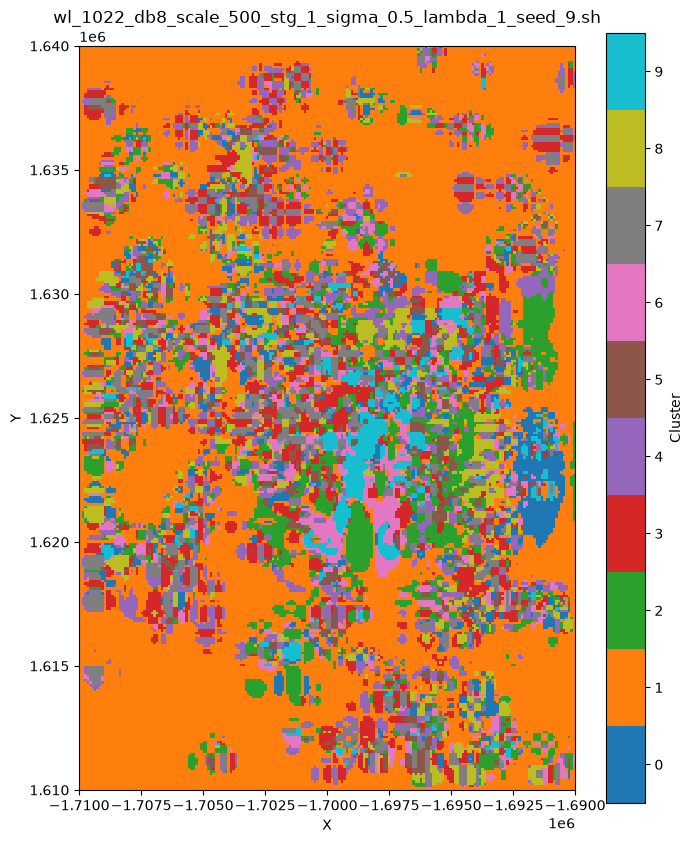

In [ ]:

coords_np = np.array(coords)
# クラスタリング
with torch.no_grad():
    embeds, cluster_labels = g_spa_enc_embed_clustering(
        g_enc_dec, num_cluster, coords_np
    )

labels = np.asarray(cluster_labels)

# 描画
fig, ax = plt.subplots(figsize=(8, 10))

cmap = plt.get_cmap("tab10", num_cluster)

im = ax.imshow(
    labels,
    origin="lower",
    extent=extent,
    cmap=cmap,
    vmin=-0.5,
    vmax=num_cluster - 0.5,
    interpolation="nearest",
    aspect="equal"
)

fig.colorbar(
    im,
    ax=ax,
    ticks=np.arange(num_cluster),
    label="Cluster"
)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_title(row["script"])

# 保存
output_path = output_dir / f"{Path(row['script']).stem}.png"

fig.savefig(output_path, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

# メモリ解放
del g_enc_dec, embeds, cluster_labels
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()    

In [32]:
g_enc_dec.g_spa_enc.stg.mu

Parameter containing:
tensor([-1.1035, -0.6234, -1.0626,  ..., -1.1044, -1.1049, -1.1055],
       device='cuda:0', requires_grad=True)

Total: 12021
Exactly zero: 87.098%
0 < gate <= 0.1: 3.585%
0.1 < gate <= 0.5: 8.335%
gate > 0.5: 0.982%
Exactly one: 0.008%
Mean gate: 0.0297


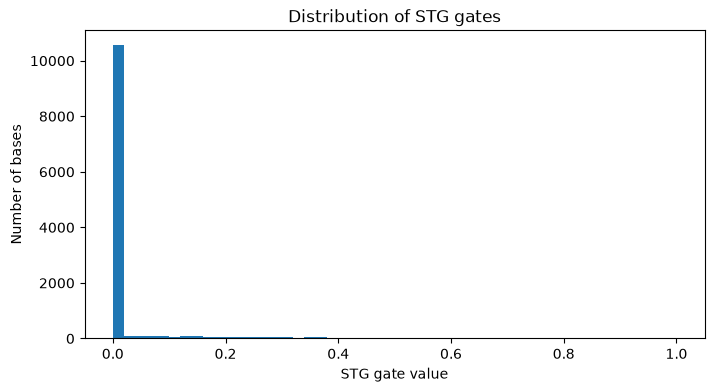

In [40]:
gate = (
    g_enc_dec.g_spa_enc.stg.mu
    .detach()
    .cpu()
    .clamp(0, 1)
    .numpy()
)

print(f"Total: {len(gate)}")
print(f"Exactly zero: {(gate == 0).mean():.3%}")
print(f"0 < gate <= 0.1: {((gate > 0) & (gate <= 0.1)).mean():.3%}")
print(f"0.1 < gate <= 0.5: {((gate > 0.1) & (gate <= 0.5)).mean():.3%}")
print(f"gate > 0.5: {(gate > 0.5).mean():.3%}")
print(f"Exactly one: {(gate == 1).mean():.3%}")
print(f"Mean gate: {gate.mean():.4f}")

plt.figure(figsize=(8, 4))
plt.hist(gate, bins=50, range=(0, 1))
plt.xlabel("STG gate value")
plt.ylabel("Number of bases")
plt.title("Distribution of STG gates")
plt.show()

Total: 12021
Exactly zero: 87.098%
0 < gate <= 0.1: 3.585%
0.1 < gate <= 0.5: 8.335%
gate > 0.5: 0.982%
Exactly one: 0.008%
Mean gate: 0.0297


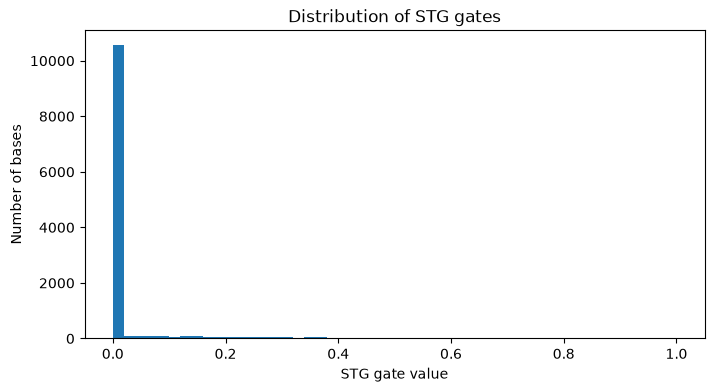

In [ ]:
gate = (
    g_enc_dec.g_spa_enc.stg.mu
    .detach()
    .cpu()
    .clamp(0, 1)
    .numpy()
)

print(f"Total: {len(gate)}")
print(f"Exactly zero: {(gate == 0).mean():.3%}")
print(f"0 < gate <= 0.1: {((gate > 0) & (gate <= 0.1)).mean():.3%}")
print(f"0.1 < gate <= 0.5: {((gate > 0.1) & (gate <= 0.5)).mean():.3%}")
print(f"gate > 0.5: {(gate > 0.5).mean():.3%}")
print(f"Exactly one: {(gate == 1).mean():.3%}")
print(f"Mean gate: {gate.mean():.4f}")

plt.figure(figsize=(8, 4))
plt.hist(gate, bins=50, range=(0, 1))
plt.xlabel("STG gate value")
plt.ylabel("Number of bases")
plt.title("Distribution of STG gates")
plt.show()

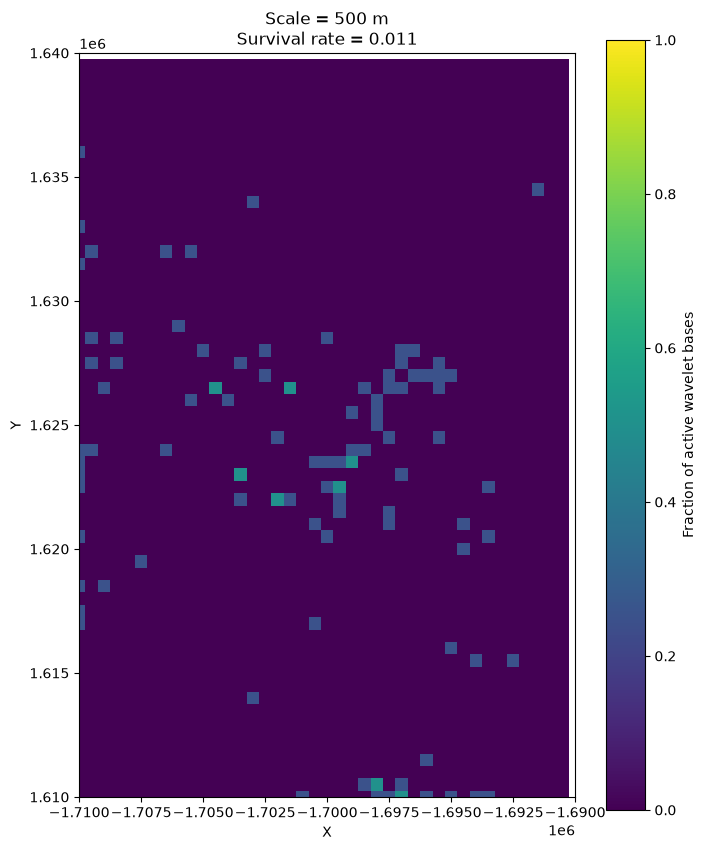

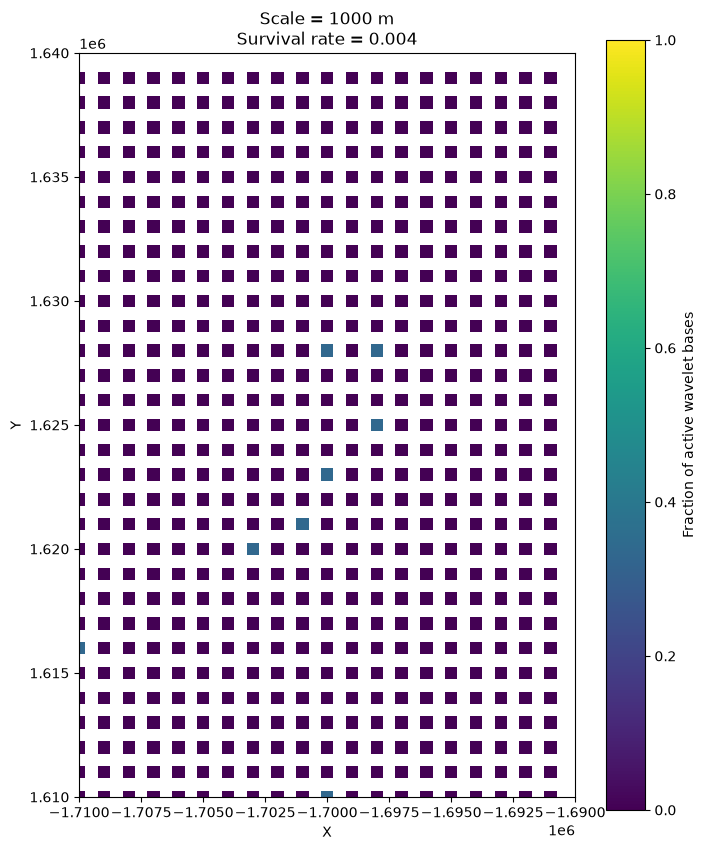

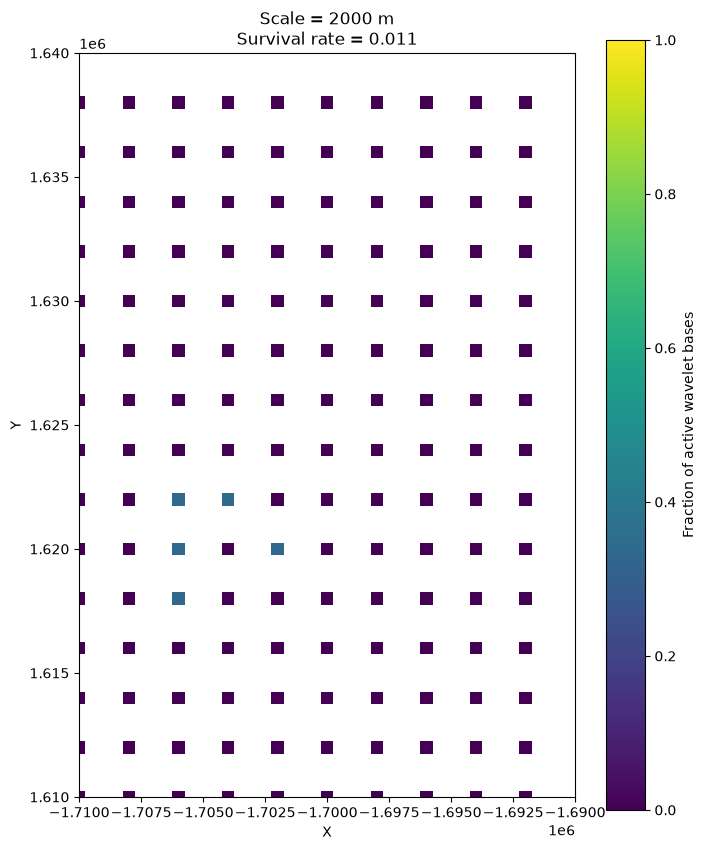

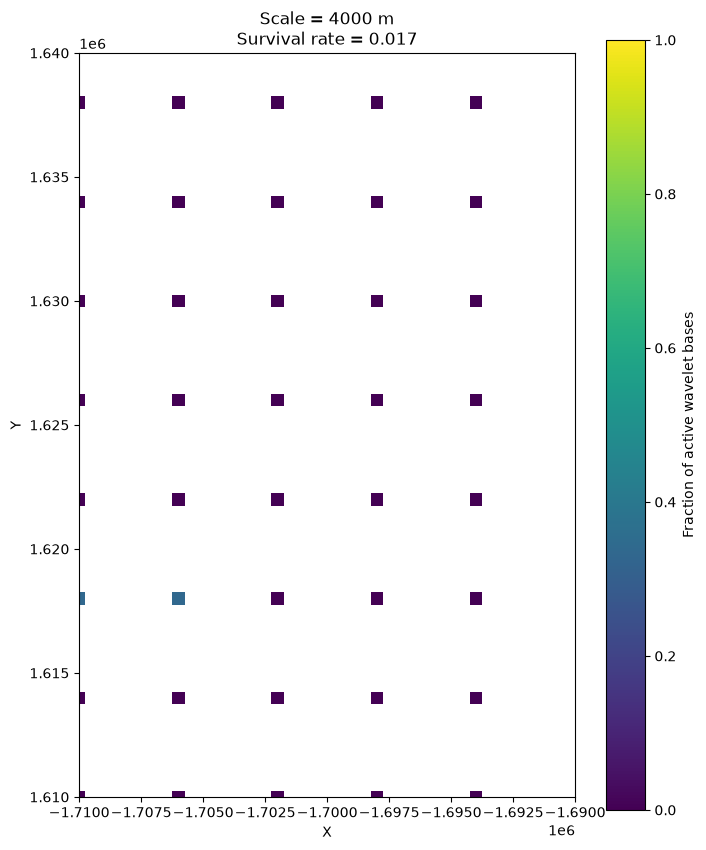

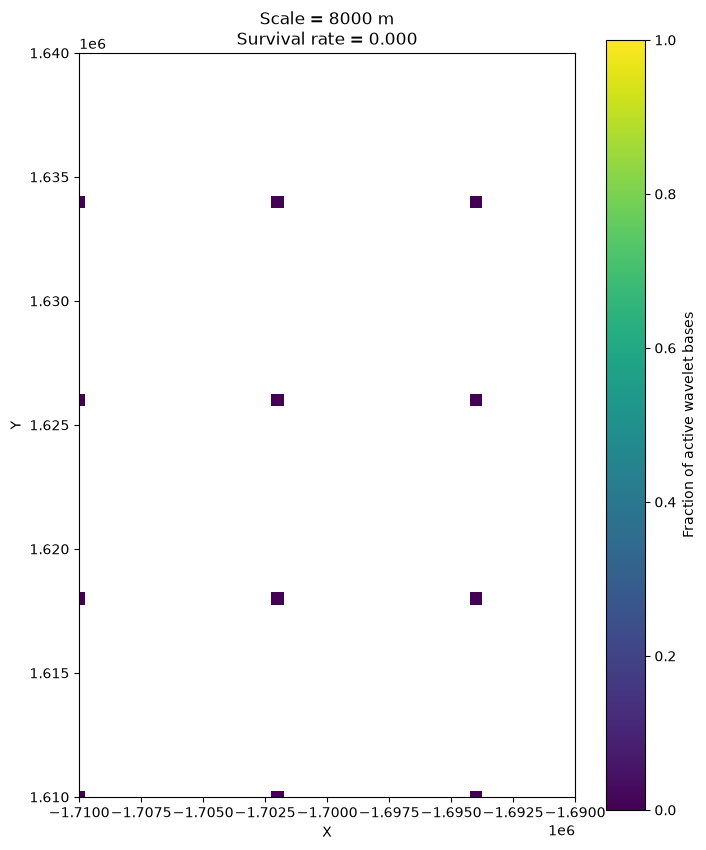

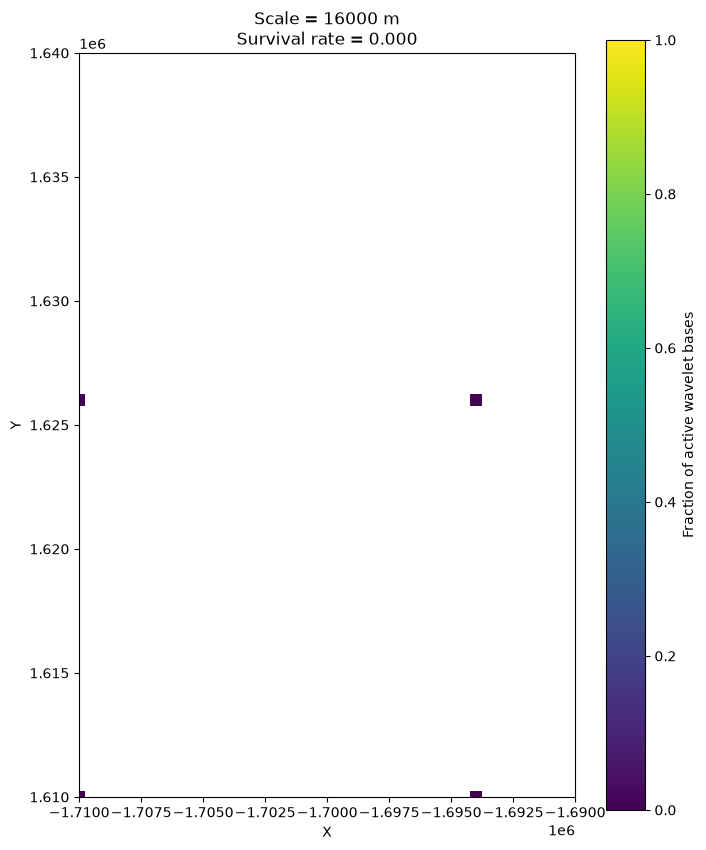

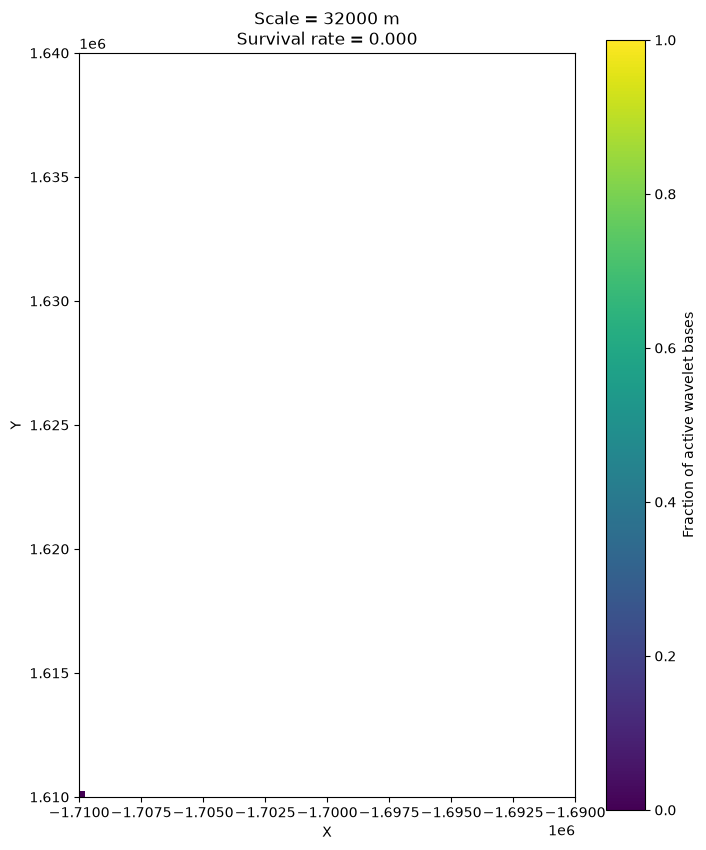

In [11]:
plot_stg_survival_by_scale(g_enc_dec.g_spa_enc)

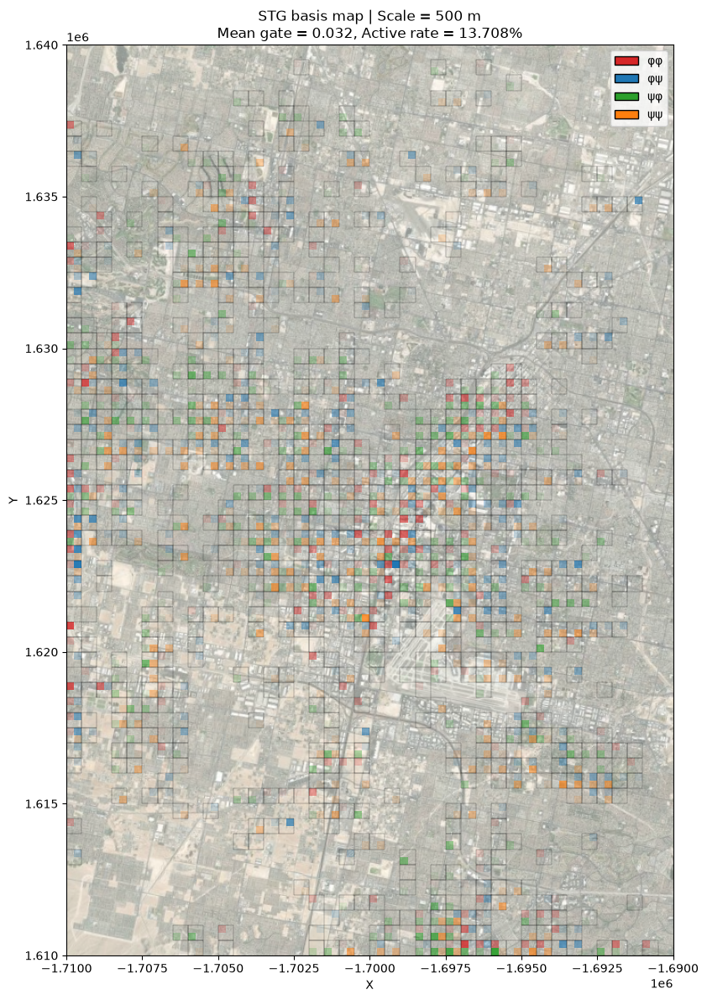

Scale 500 m | Basis points: 2400 | Mean gate: 0.0321 | Active: 13.71%


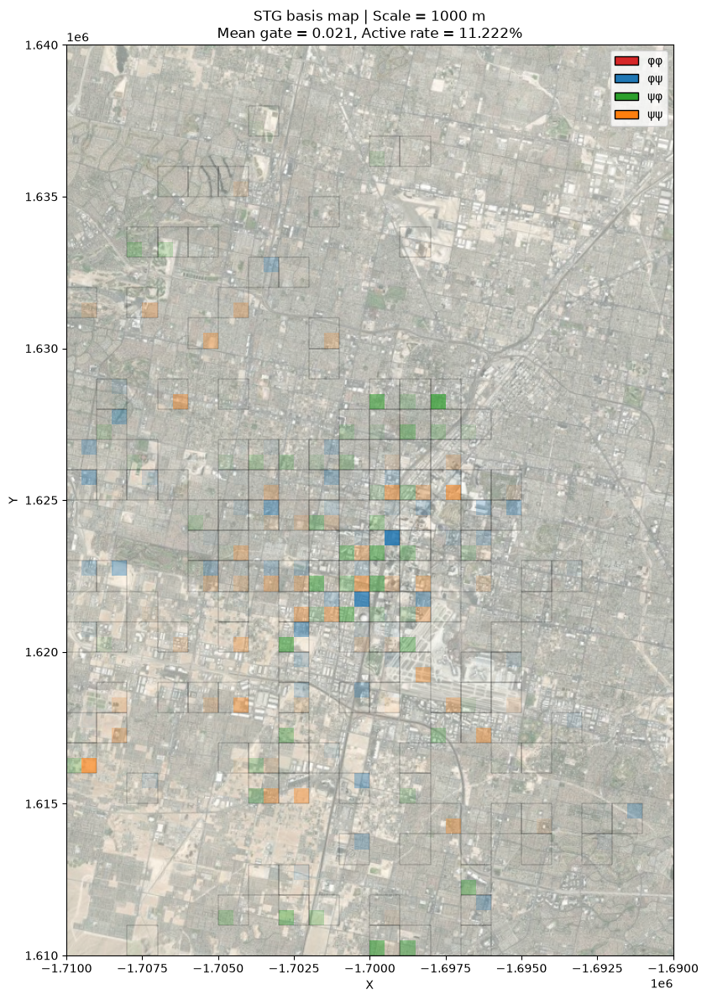

Scale 1000 m | Basis points: 600 | Mean gate: 0.0211 | Active: 11.22%


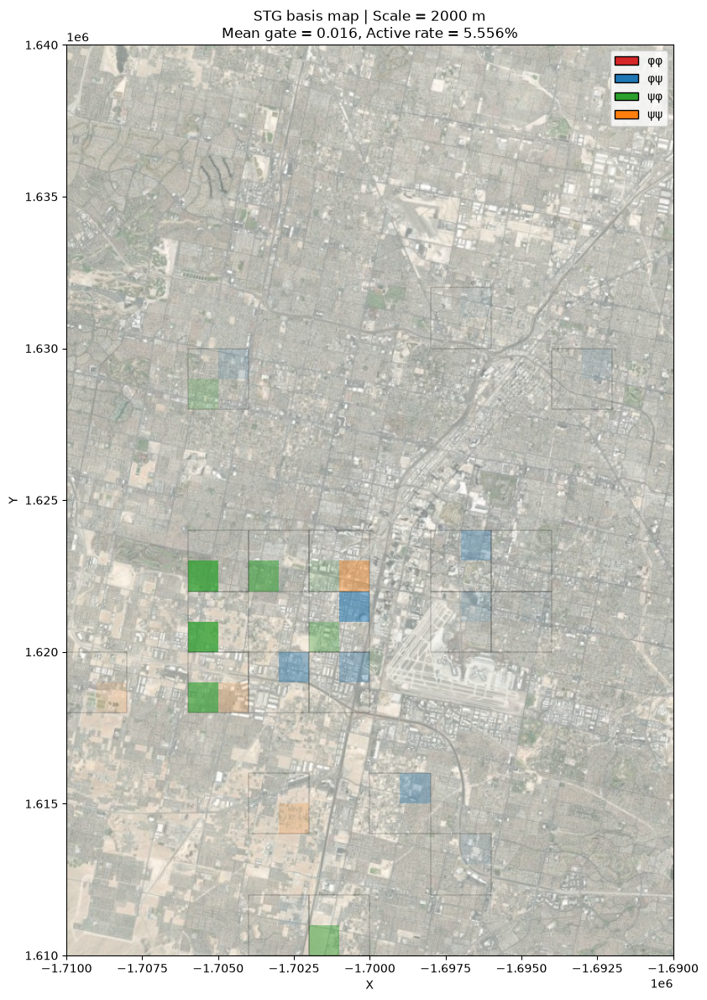

Scale 2000 m | Basis points: 150 | Mean gate: 0.0156 | Active: 5.56%


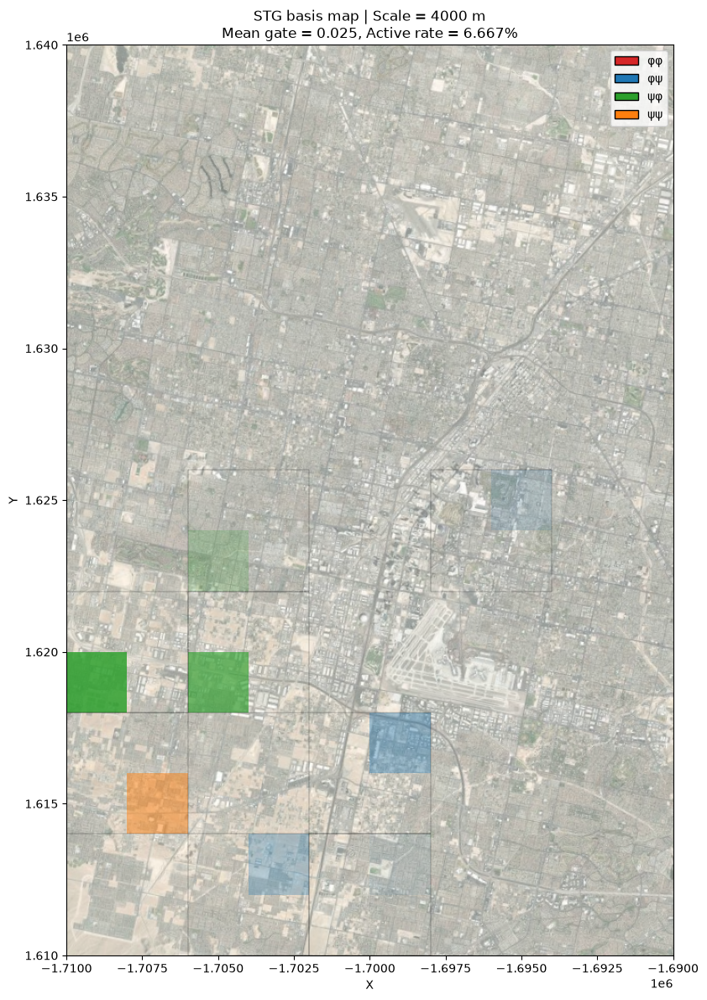

Scale 4000 m | Basis points: 40 | Mean gate: 0.0254 | Active: 6.67%


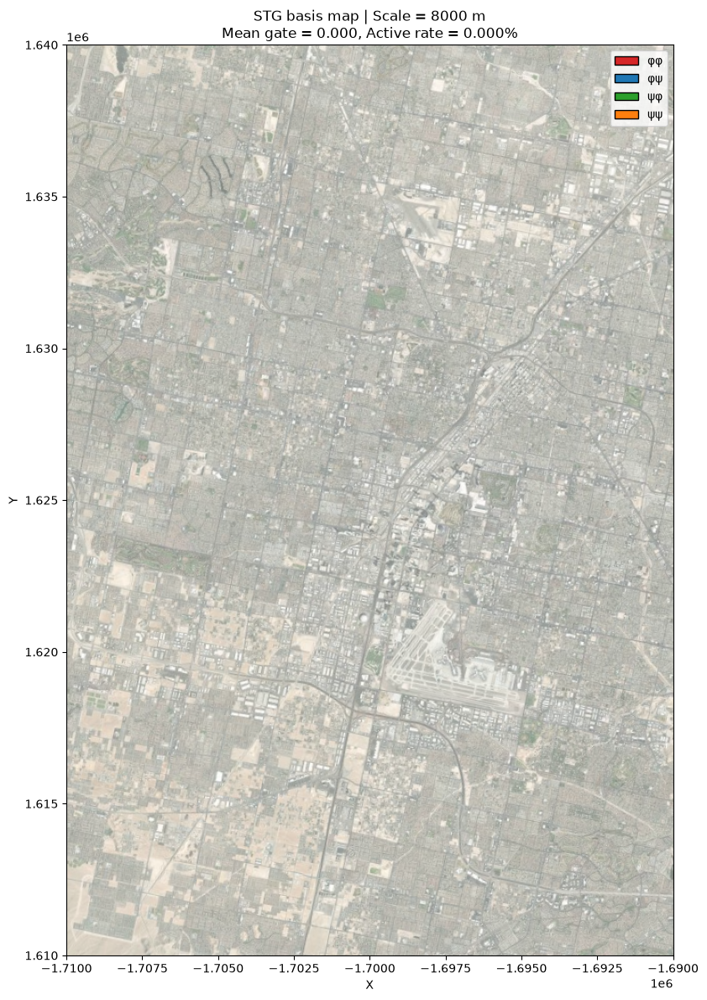

Scale 8000 m | Basis points: 12 | Mean gate: 0.0000 | Active: 0.00%


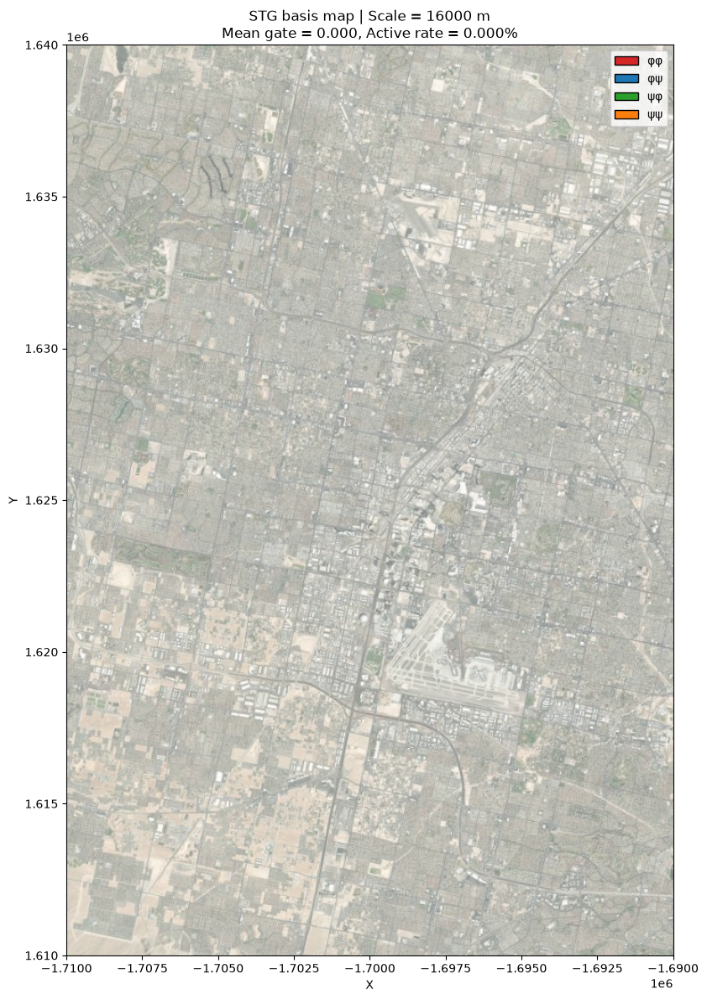

Scale 16000 m | Basis points: 4 | Mean gate: 0.0000 | Active: 0.00%


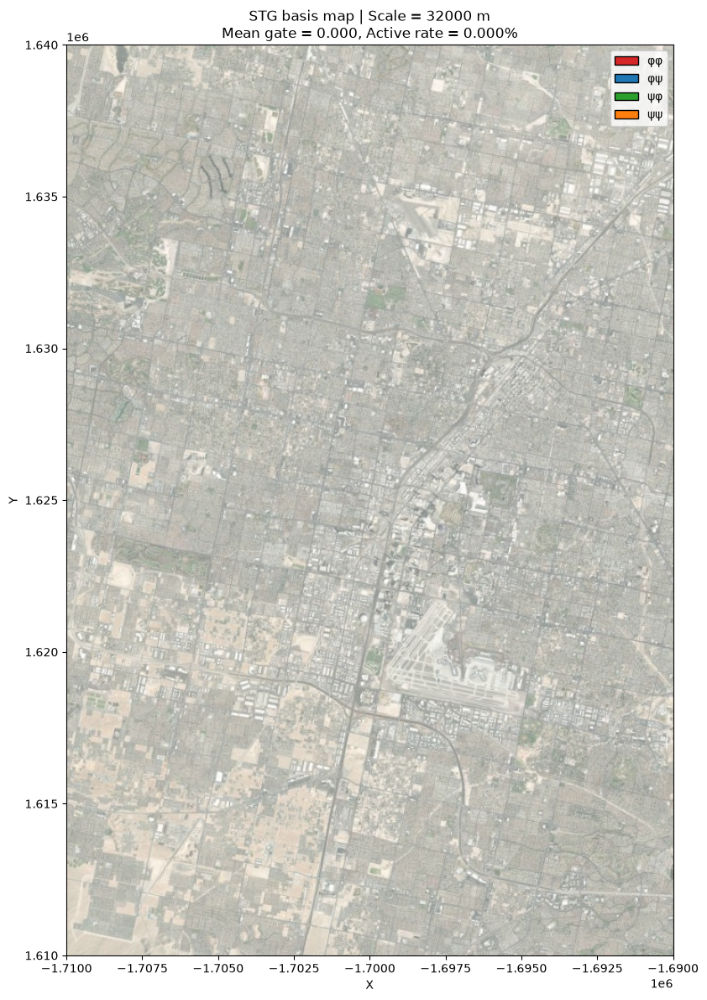

Scale 32000 m | Basis points: 1 | Mean gate: 0.0000 | Active: 0.00%


In [12]:
plot_stg_basis_type_map(g_enc_dec.g_spa_enc, save_dir=Path(exp_dir) / "stg_basis_maps", show=True, dpi=150)